In [1]:
import requests
from pathlib import Path
 
URL = "https://github.com/bigdatawirtz/datasets/raw/refs/heads/main/datasets/meteo_alvedro_2021_2025.csv"
resposta = requests.get(URL, timeout=30)
resposta.raise_for_status()
destino = Path("../datos/raw/meteo_alvedro_2021_2025.csv")
destino.parent.mkdir(exist_ok=True,parents=True)
destino.write_bytes(resposta.content)   # bytes: tal como chega


81825

# Analysis Process

Bytes 81825
The data starts in line 7
Command Separator ;
Date Formats -> YYYY-MM-DD && DD/MM/YYY
Decimals ,
Precipation could be "Ip" and Empty
NA and -9999 rare results



In [2]:
import pandas as pd
dataFrame = pd.read_csv("../datos/raw/meteo_alvedro_2021_2025.csv",thousands=".", decimal=",",sep=";", encoding="latin-1",skiprows=6)
dataFrame = dataFrame.rename(columns={
    "Data": "data",
    "Temp. media (ºC)": "tmed",
    "Temp. máxima (ºC)": "tmax",
    "Temp. mínima (ºC)": "tmin",
    "Precipitación (mm)": "prec",
    "Vento medio (km/h)": "wind",
    "Humidade relativa (%)": "hum",
    "Presión (hPa)": "pres",
})


dataFrame

,data,tmed,tmin,tmax,hum,prec,wind,pres
0,2021-01-01,5.9,3.3,9.1,87,"12,2",11.0,1015.7
1,2021-01-02,5.5,3.1,9.7,91,"9,8",6.4,1019.8
2,2021-01-03,5.6,3.0,8.4,92,"12,4",8.5,1018.9
3,2021-01-04,3.6,-0.3,6.8,92,"4,7",7.8,1015.4
4,2021-01-05,2.8,-1.5,9.4,94,"1,2",6.2,1014.6
...,...,...,...,...,...,...,...,...
1807,2025-06-10,20.8,15.6,27.6,80,Ip,6.2,1015.7
1808,2021-04-16,10.0,3.6,17.2,56,"0,0",11.7,1020.1
1809,2022-05-21,19.9,10.9,24.7,81,"2,9",5.8,1015.6
1810,2025-10-12,17.6,9.9,24.9,74,"0,0",5.8,1018.8


In [3]:
# Column types
print(dataFrame.dtypes)

# Column "Precipitacion" must be numeric but in reality the type is Object
# We will see why this column has this column type
col = "prec"


dataFrame[col] = dataFrame[col].astype(str).str.replace(",", ".", regex=False)
dataFrame[col] = pd.to_numeric(dataFrame[col], errors="coerce")
invalidos = dataFrame.loc[dataFrame[col].isna(),col]

print(len(invalidos))
dataFrame.dtypes


data        str
tmed    float64
tmin    float64
tmax    float64
hum       int64
prec        str
wind    float64
pres    float64
dtype: object
129


data        str
tmed    float64
tmin    float64
tmax    float64
hum       int64
prec    float64
wind    float64
pres    float64
dtype: object

# Graphics before clean

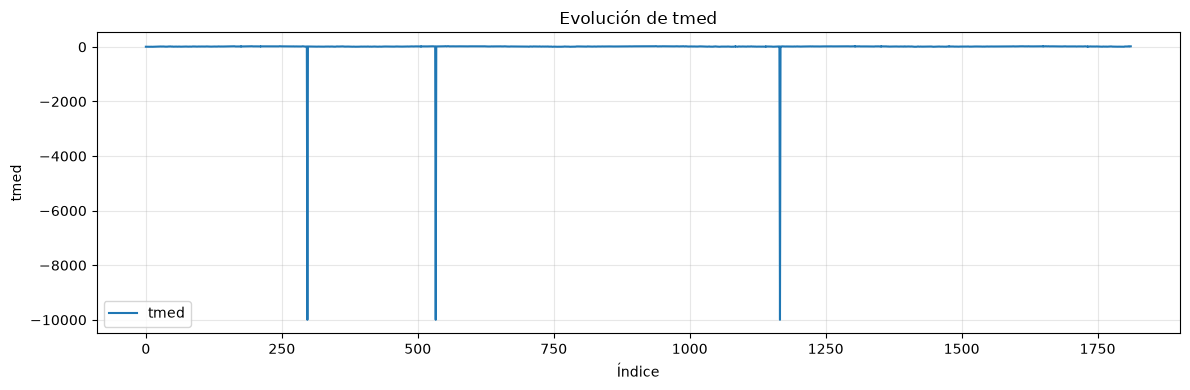

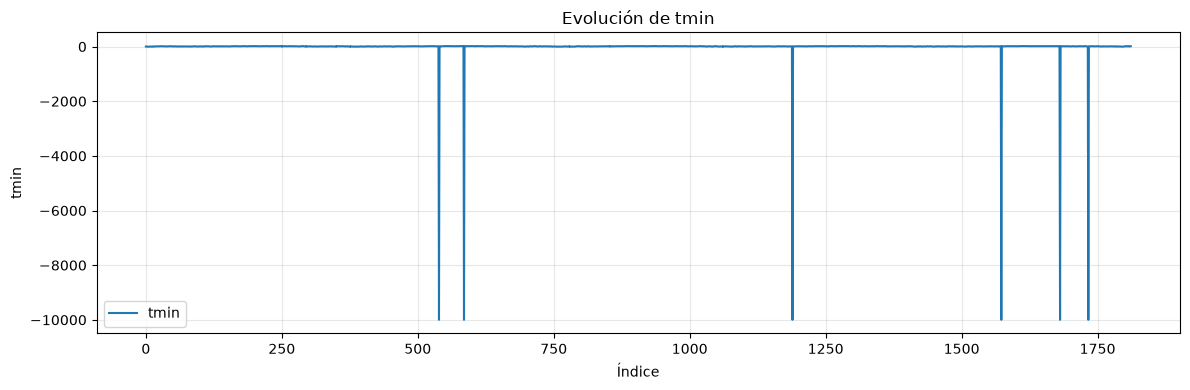

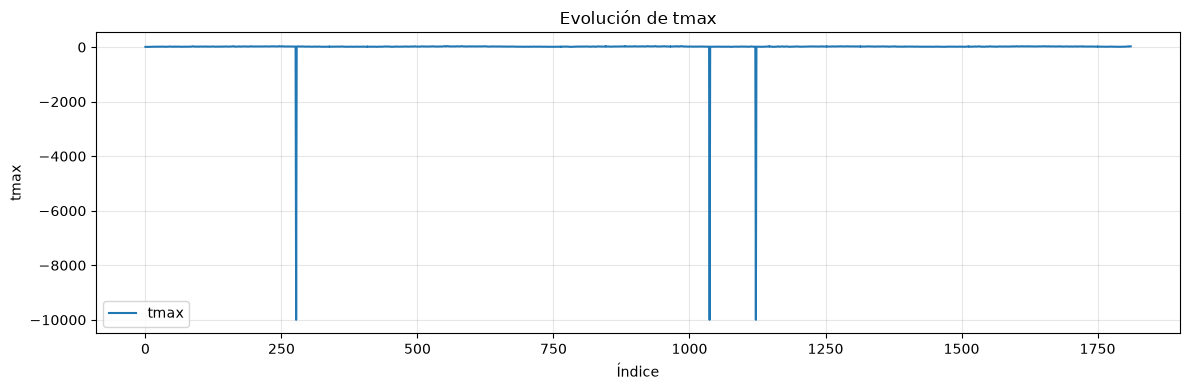

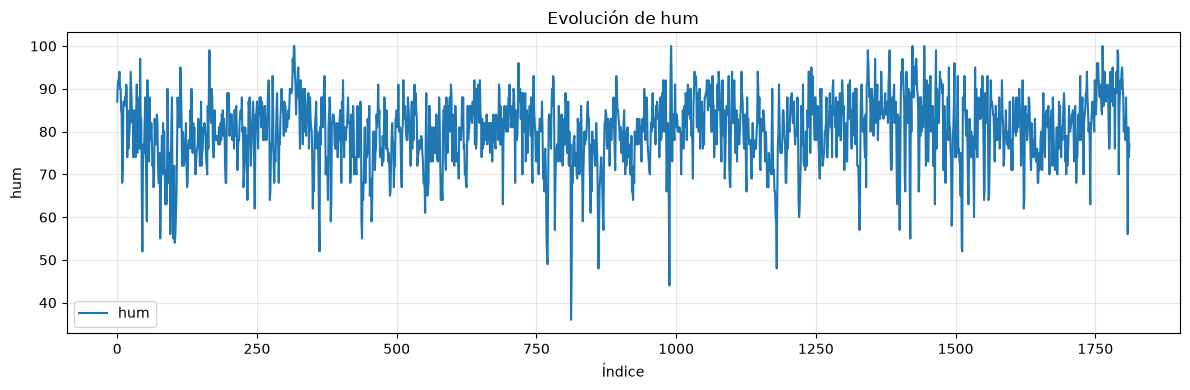

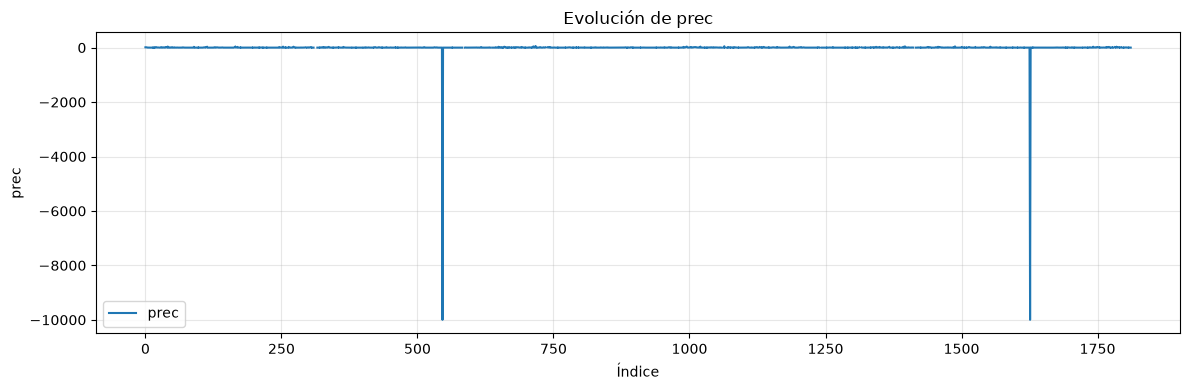

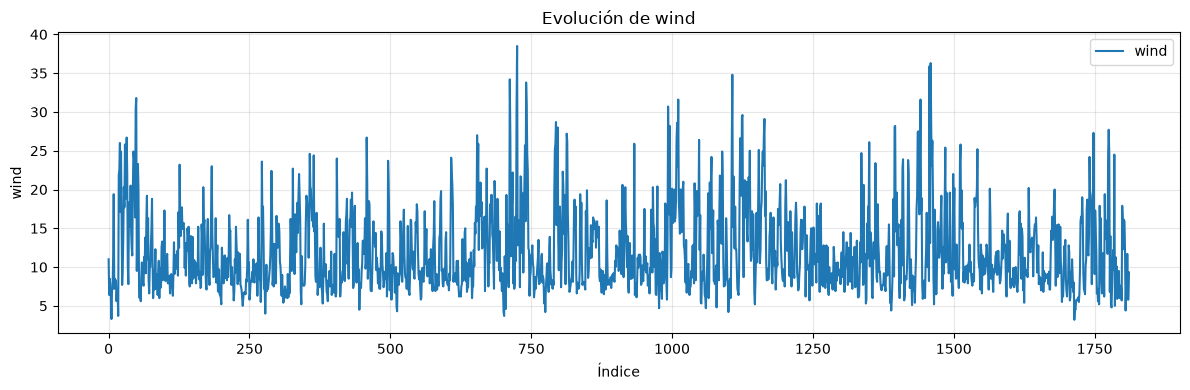

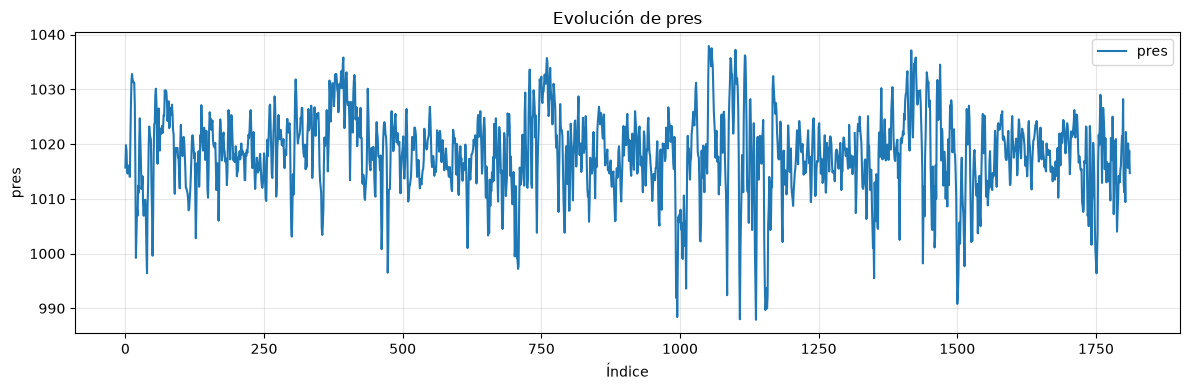

In [4]:
import matplotlib.pyplot as plt
import pandas as pd
for columna in dataFrame.columns:
    # Saltar columnas que no sean numéricas
    if not pd.api.types.is_numeric_dtype(dataFrame[columna]):
        continue

    plt.figure(figsize=(12, 4))
    plt.plot(dataFrame.index, dataFrame[columna], label=columna)

    plt.title(f'Evolución de {columna}')
    plt.xlabel('Índice')
    plt.ylabel(columna)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

# Clean duplicates


In [5]:

print("Filas duplicadas:", dataFrame.duplicated().sum())
print("Datas repetidas:", dataFrame["data"].duplicated().sum())
dataFrame = dataFrame.drop_duplicates()

Filas duplicadas: 8
Datas repetidas: 13


# Clean imposible values

In [6]:
print(dataFrame.describe().round(1))

# We see that temperatures has values imposible we gonna fix that. We are goinf to put null to this values imposibles.

dataFrame.loc[dataFrame["tmed"]< 0, "tmed"] = pd.NA
dataFrame.loc[dataFrame["tmin"]< 0, "tmin"] = pd.NA
dataFrame.loc[dataFrame["tmax"]< 0, "tmax"] = pd.NA
dataFrame.loc[dataFrame["prec"]< 0, "prec"] = pd.NA
print("----------------------------------------------------------")
print(dataFrame.describe().round(1))




         tmed    tmin    tmax     hum    prec    wind    pres
count  1795.0  1798.0  1795.0  1804.0  1676.0  1804.0  1803.0
mean     -2.2   -23.1     2.5    80.2    -8.8    11.9  1018.2
std     409.2   577.4   409.4     8.1   345.5     5.2     7.4
min   -9999.0 -9999.0 -9999.0    36.0 -9999.0     3.2   987.9
25%      11.3     7.1    15.4    76.0     0.0     8.1  1014.4
50%      14.7    10.9    18.9    81.0     0.2    10.4  1018.5
75%      18.0    14.0    22.8    86.0     3.2    14.9  1022.5
max      31.3    21.1    39.2   100.0    58.7    38.5  1037.9
----------------------------------------------------------
         tmed    tmin    tmax     hum    prec    wind    pres
count  1792.0  1742.0  1792.0  1804.0  1674.0  1804.0  1803.0
mean     14.6    10.6    19.2    80.2     3.1    11.9  1018.2
std       4.3     4.4     4.9     8.1     6.2     5.2     7.4
min       2.1     0.0     6.7    36.0     0.0     3.2   987.9
25%      11.4     7.4    15.4    76.0     0.0     8.1  1014.4
50%      14

# We are gonna transform the column date into DATE type

In [7]:
print(dataFrame["data"].tail(20))


def converter_datas(data, formatos):
    resultado = pd.Series(pd.NaT, index=data.index, dtype="datetime64[ns]")
    for formato in formatos:
        intento = pd.to_datetime(data, format=formato, errors="coerce")
        resultado = resultado.fillna(intento)
    return resultado, data[resultado.isna()]



dataFrame["data"], invalids = converter_datas(dataFrame["data"], ["%Y-%m-%d", "%d/%m/%Y"]) 
print("Sen converter:", invalids.tolist())
print(dataFrame.dtypes)


1784    2025-12-17
1785    2025-12-18
1786    2025-12-19
1787    2025-12-20
1788    2025-12-21
1789    2025-12-22
1790    2025-12-23
1791    2025-12-24
1792    2025-12-25
1793    2025-12-26
1794    2025-12-27
1795    2025-12-28
1796    2025-12-29
1797    2025-12-30
1798    2025-12-31
1799    2025-11-22
1800    2024-05-18
1806    2021-07-01
1808    2021-04-16
1809    2022-05-21
Name: data, dtype: str
Sen converter: []
data    datetime64[ns]
tmed           float64
tmin           float64
tmax           float64
hum              int64
prec           float64
wind           float64
pres           float64
dtype: object


In [8]:
dataFrame.isna().sum()

data      0
tmed     12
tmin     62
tmax     12
hum       0
prec    130
wind      0
pres      1
dtype: int64

# Decision of nulls values

## Temperature and Presion nulls
    - We are gonna to interpolate the nulls values with next values to it.

## Prec nulls
    - Its better to not invent prec data, so we have to stay the null values as it is.

In [9]:
# We order the data for the dates
dataFrame = dataFrame.set_index("data").sort_index()

for col in ["tmed", "tmax", "tmin", "pres"]:
    # We use the interpolate method to transform null values into data using method "time". This method use the datetime to interpolate the data
    # We round the decimals to 1 decimal because all the data was in this format
    dataFrame[col] = dataFrame[col].interpolate(method="time").round(1)

# Comprobation of nulls values
dataFrame.isna().sum()

tmed      0
tmin      0
tmax      0
hum       0
prec    130
wind      0
pres      0
dtype: int64

# Save data

In [10]:
clean_data = Path("../datos/clean")
clean_data.mkdir(exist_ok=True)
dataFrame.to_csv(clean_data / "meteo_alvedro_2021_2025.csv")   # UTF-8, separador "," e decimal "."
print("Gardado:", clean_data / "meteo_alvedro_2021_2025.csv")

Gardado: ../datos/clean/meteo_alvedro_2021_2025.csv


# Analyze data

## Cal foi a temperatura media de cada ano? Obsérvase algunha tendencia?

In [11]:
# Group tmed in year data with method resample YS -> Year Start
year = dataFrame.resample("YS").agg({"tmed":"mean"})
year

# I do not observe any clear trend; the average temperature remains relatively stable over time.

,tmed
data,
2021-01-01,14.131593
2022-01-01,14.992329
2023-01-01,14.905831
2024-01-01,14.456011
2025-01-01,14.482787


## Cal é, de media, o mes máis chuvioso e o máis seco?

In [12]:
# We group the data by month and year
mensual = dataFrame.groupby(dataFrame.index.month)["prec"].mean().round(2)
MESES = ["xan", "feb", "mar", "abr", "mai", "xuñ", "xul", "ago", "set", "out", "nov", "dec"]
mensual.index = [MESES[m - 1] for m in mensual.index]
mensual.round(1)

# Rainy month is November
# Dry month is August/July

xan    4.4
feb    3.6
mar    2.9
abr    2.9
mai    2.2
xuñ    1.8
xul    0.5
ago    0.5
set    2.6
out    5.3
nov    5.6
dec    5.2
Name: prec, dtype: float64

## Cantos días de choiva hai cada mes? Considera día de choiva o que ten polo menos 1 mm (indica o criterio que uses).

In [13]:
# We group data by month 
month = dataFrame.resample("MS").agg({"prec": lambda x : (x >=1).sum()})
month

,prec
data,
2021-01-01,17
2021-02-01,14
2021-03-01,6
2021-04-01,10
2021-05-01,16
2021-06-01,10
2021-07-01,8
2021-08-01,3
2021-09-01,13


## Cal foi o día máis quente e o máis frío de cada ano?

In [14]:
# Date Tmax
date_of_tmax = dataFrame.groupby(dataFrame.index.year)["tmax"].idxmax()
print(dataFrame.loc[date_of_tmax,["tmax"]])

date_of_tmin = dataFrame.groupby(dataFrame.index.year)["tmin"].idxmin()
print(dataFrame.loc[date_of_tmin,["tmin"]])

            tmax
data            
2021-09-06  35.9
2022-07-14  34.4
2023-08-23  37.2
2024-03-19  39.2
2025-03-21  36.2
            tmin
data            
2021-03-27   0.0
2022-04-03   0.1
2023-12-17   0.1
2024-12-15   0.0
2025-02-08   0.3


# 4.5 Amosa

# T media

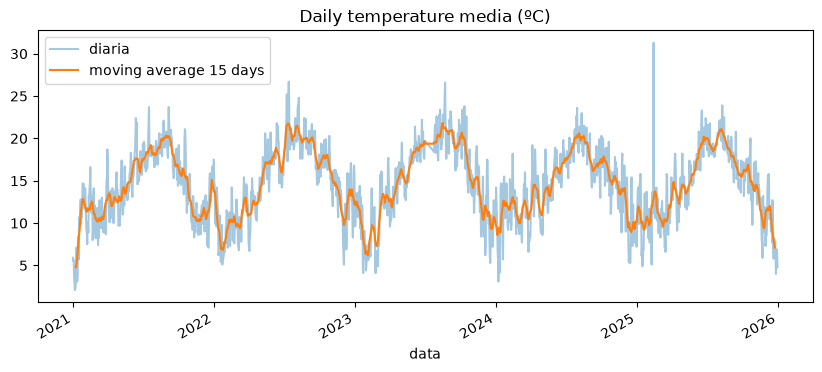

In [15]:
fig, ax = plt.subplots(figsize=(10, 4))
dataFrame["tmed"].plot(ax=ax, alpha=0.4, label="diaria")
dataFrame["tmed"].rolling(15, center=True).mean().plot(ax=ax, label="moving average 15 days")
ax.set_title("Daily temperature media (ºC)")
ax.legend()
plt.show()

## Prec media

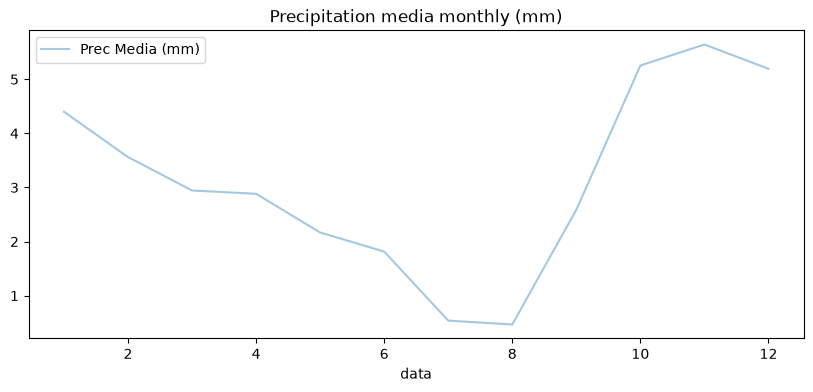

In [16]:
fig, ax = plt.subplots(figsize=(10, 4))
(dataFrame.groupby(dataFrame.index.month)["prec"].mean()).plot(ax=ax, alpha=0.4, label="Prec Media (mm)")
ax.set_title("Precipitation media monthly (mm)")
ax.legend()
plt.show()

## comparación do último ano coa media

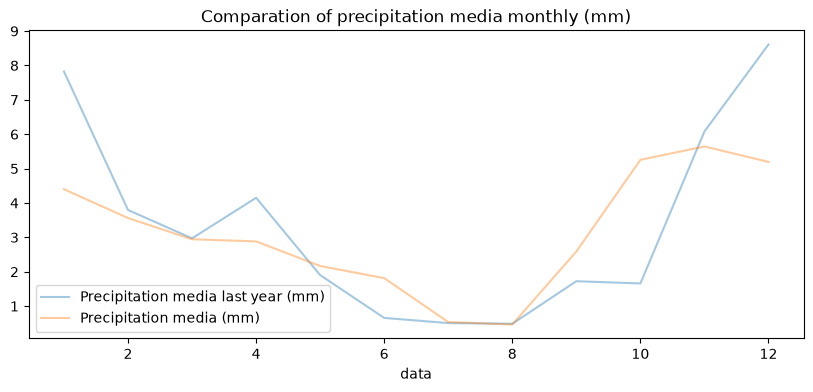

In [17]:
fig, ax = plt.subplots(figsize=(10, 4))
last_year = dataFrame.index.year.max()

prec_last_year = dataFrame[dataFrame.index.year == last_year]["prec"]
prec_last_year.groupby(prec_last_year.index.month).mean().plot(ax=ax, alpha=0.4, label="Precipitation media last year (mm)")
dataFrame.groupby(dataFrame.index.month)["prec"].mean().plot(ax=ax, alpha=0.4, label="Precipitation media (mm)")
ax.set_title("Comparation of precipitation media monthly (mm)")
ax.legend()
plt.show()

# 4.6 Mide a eficiencia
1. Calcula a amplitude térmica diaria (tmax − tmin) de dúas formas e mide o tempo con %timeit:
    - Cun bucle for que percorra as filas.
    - Cunha operación vectorizada de pandas-numpy
2. Repite a medición cun DataFrame cinco veces máis grande (por exemplo, con pd.concat) e explica en dúas ou tres frases que observas e por que.


In [18]:
%%timeit
t_termic={}
for index,tmax,tmin in zip(dataFrame.index.date,dataFrame["tmax"],dataFrame["tmin"]):
    t_termic[index] = tmax -tmin

t_termic

395 μs ± 24.4 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


In [19]:
%%timeit
t_termic= dataFrame["tmax"]-dataFrame["tmin"]

t_termic

23.7 μs ± 570 ns per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


In [20]:

dataFrame_big = pd.concat([dataFrame] * 5)

In [21]:
%%timeit
t_termic={}
for index,tmax,tmin in zip(dataFrame_big.index.date,dataFrame_big["tmax"],dataFrame_big["tmin"]):
    t_termic[index] = tmax -tmin

t_termic

1.88 ms ± 30.5 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


In [22]:
%%timeit
t_termic= dataFrame_big["tmax"]-dataFrame_big["tmin"]

t_termic

25.8 μs ± 1.89 μs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


## Anwser
What we can see is that as the dataframe gets larger, it takes longer to complete execution; we can also see that the pandas functions are faster than the native ones.

# SQL
## Connection to Progresql

In [23]:
from sqlalchemy import create_engine
from dotenv import load_dotenv
import os

load_dotenv()

engine = create_engine(
    f"postgresql+psycopg2://{os.getenv('POSTGRES_USER')}:"
    f"{os.getenv('POSTGRES_PASSWORD')}@localhost:"
    f"{os.getenv('POSTGRES_PORT')}/{os.getenv('POSTGRES_DB')}"
)

dataFrame.to_sql(
    name="datos_limpios",
    con=engine,
    if_exists="replace",
    index=True,
    index_label="data"
)


804